In [1]:
# %%
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib as mpl


In [2]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIX Two Text", "STIXGeneral"],
    "mathtext.fontset": "stix",

    "font.size": 26,
    "axes.labelsize": 28,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
    "legend.fontsize": 22,

    "axes.linewidth": 1.2,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
})

In [3]:
# Source - https://stackoverflow.com/a/71692086
# Posted by Gabriele
# Retrieved 2026-06-30, License - CC BY-SA 4.0

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

# %%
e = np.e 
pi=np.pi
r_set = np.array([e**(-0.75), e**(-0.5),e**(-0.25)])
KA = 0.001
alpha0_set = np.linspace(0.5, 1, 6) * np.pi
phi_set = np.array([0.13, 0.26, 0.52])



# %%
# Initialize a list to accumulate dataframes from all files
all_data = pd.read_csv("./calculated_defects_data.csv")
print(list(all_data))
all_data=all_data[all_data['max_delta']>=10]
all_data=all_data[all_data['min_delta']<=-10]

math_data = pd.read_csv('fig7data_mathematica.csv')
l_array = np.array(math_data['l'])
phi_array = np.array(math_data['phi'])
f_array = np.array(math_data['f']) # f=1-log(r)/log(rho) from mathematica


ru_set = (np.unique(all_data['r_param']))
l = len(ru_set)
print(ru_set)

['alpha0', 'phi_param', 'r_param', 'KA', 't', 'max_x', 'max_y', 'min_x', 'min_y', 'r_max', 'r_min', 'phi_max', 'phi_min', 'max_delta', 'min_delta', 'rho', 'total_free_energy']
[0.22313016 0.36787944 0.47236655 0.60653066 0.68728928 0.77880078]


In [4]:
all_data['total_free_energy']/=4
rho_set=np.unique(all_data['rho'])
rho_set=np.array(sorted(rho_set, reverse=True))
all_data['dphi']= all_data['phi_max']-all_data['phi_min']

0.195


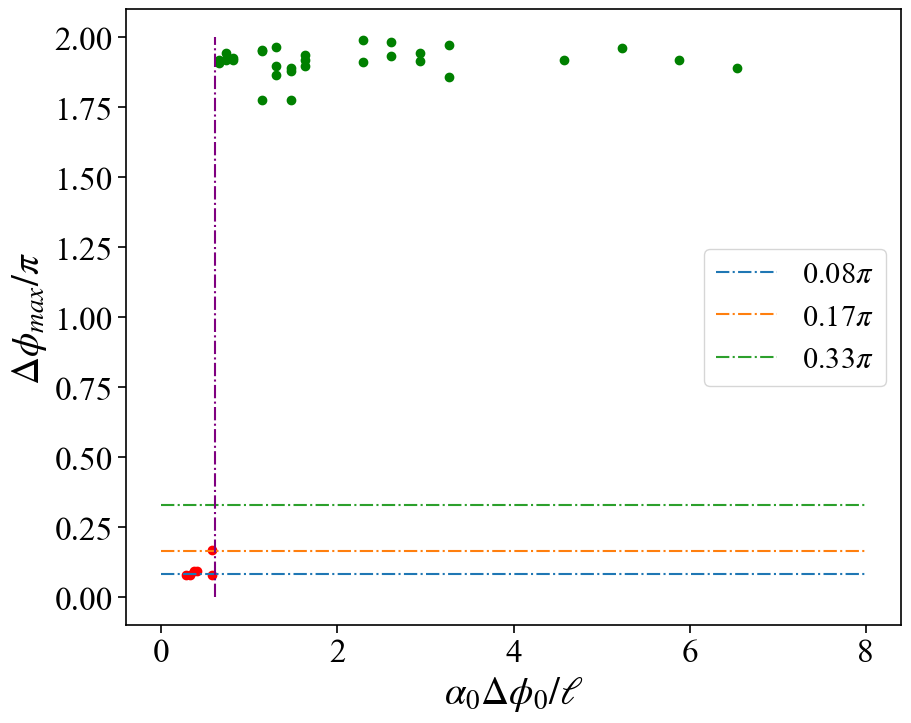

In [12]:
fig, axs = plt.subplots(1, 1, figsize=(10, 8), sharex=False)
xplot = np.linspace(0, 8, 100)
yplot = np.linspace(0, 2, 100)
cross_min = 100
stay_max = 0
for phi in phi_set:
    axs.plot(xplot, np.ones_like(xplot)*2*phi/pi, '-.', label = '{0:.2f}$\\pi$'.format(2*phi/pi))
    for rho in rho_set[:]:
        r=np.sqrt(rho)
        for alpha0 in alpha0_set[1:]:
            data = all_data[(all_data['alpha0'] == alpha0) &  np.isclose(all_data['rho'], rho) & (all_data['phi_param'] == phi)&  np.isclose(all_data['r_param'], r)]
            if np.max(data['dphi'])>pi:
                axs.scatter(alpha0*2*phi/np.log(1/rho),np.max(data['dphi'])/pi,  color = 'green')
                if alpha0*2*phi/np.log(1/rho)<cross_min:
                    cross_min=2*alpha0*phi/np.log(1/rho)
            if np.max(data['dphi'])<=pi:
                axs.scatter(alpha0*2*phi/np.log(1/rho), np.max(data['dphi'])/pi,  color = 'red')
                if alpha0*2*phi/np.log(1/rho)>stay_max:
                    stay_max=2*alpha0*phi/np.log(1/rho)

plt.plot(np.ones_like(yplot)*(cross_min+stay_max)*0.5, yplot, '-.', color ='purple')
threshold = ((cross_min+stay_max)*0.5)
print(threshold/(pi))
axs.set_ylabel("$\\Delta\\phi_{max}/\\pi$")
# axs[1].set_ylabel("$F$")
axs.set_xlabel("$\\alpha_0 \\Delta \\phi_0/\\ell$")
axs.legend()
plt.show()

2.5132741228718345
saved


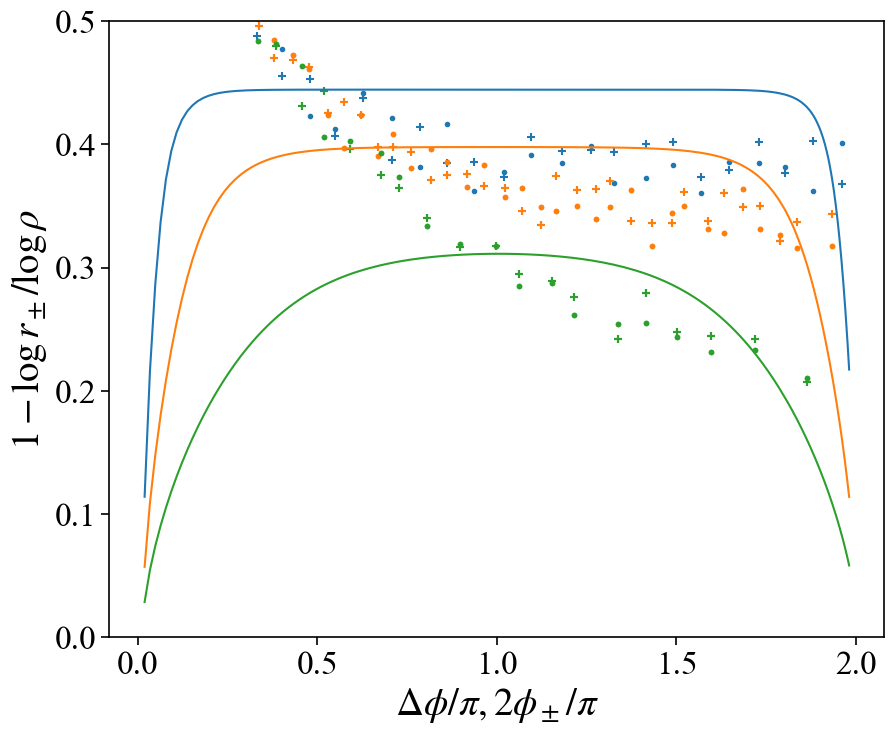

In [19]:
plt.rcParams.update({'font.size': 22})
color_array = np.array(['tab:blue', 'tab:orange', 'tab:green'])
for alpha0 in alpha0_set[3:4]:
    print(alpha0)
    for phi in phi_set[-1:]:
        fig, axs = plt.subplots(1, 1, figsize=(10, 8), sharex=False)
        counter = 0
        for i, rho in np.ndenumerate(rho_set):
            r=rho**0.5
            c=1/np.log(rho)
            l = np.log(1/rho)
            data = all_data[np.isclose(all_data['alpha0'], alpha0) &  np.isclose(all_data['r_param'], r) & np.isclose(all_data['phi_param'], phi) & np.isclose(all_data['rho'], rho)]
            if len(data)>10:
                axs.scatter( (data['phi_max']-data['phi_min'])/pi, 1-c*np.log(data['r_min']), marker = '.', label = "$f(r_-, \\Delta\\phi), \\ell$ = {0:.2f} (Simulation)".format(l), color = color_array[i[0]])
                axs.scatter( (data['phi_max']-data['phi_min'])/pi, 1-c*np.log(data['r_max']), marker = '+', label = "$f(r_+, \\Delta\\phi), \\ell$ = {0:.2f} (Simulation)".format(l), color = color_array[i[0]])
                indices = np.isclose(l_array, l)
                # print(l, indices)
                axs.plot(phi_array[indices], f_array[indices], label = "$\\ell$ = {0:.2f} (Theory)".format(l), color = color_array[i[0]])
                # axs[1].scatter(data['phi_min']/pi, 1-c*np.log(data['r_min']))
                counter+=1
        if counter>=2:
            # axs.set_title("$\\alpha_0$={0:.2f}$\\pi$, $\\Delta\\phi_0$={1:.2f}$\\pi$, $r_0 = \\rho$^0.5, $f(r, \\Delta\\phi)= 1-\\log(r)/\\ell$".format(alpha0/pi, 2*phi/pi))
            axs.set_xlabel("$\\Delta\\phi/\\pi, 2\\phi_\\pm/\\pi$")
            # axs[1].set_xlabel("$\\phi (\\delta_{min})/\\pi$")
            axs.set_ylabel("$1-\\log r_\\pm /\\log\\rho$")
            # axs[0].set_ylabel("$f(r+)$")
            # axs.legend() 
            # axs[0].set_ylim(0, 0.5)
            axs.set_ylim(0, 0.5)
            fig.savefig("trajectory_fast.pdf", bbox_inches="tight")
            print("saved")
            plt.show()
        else:
            plt.close()

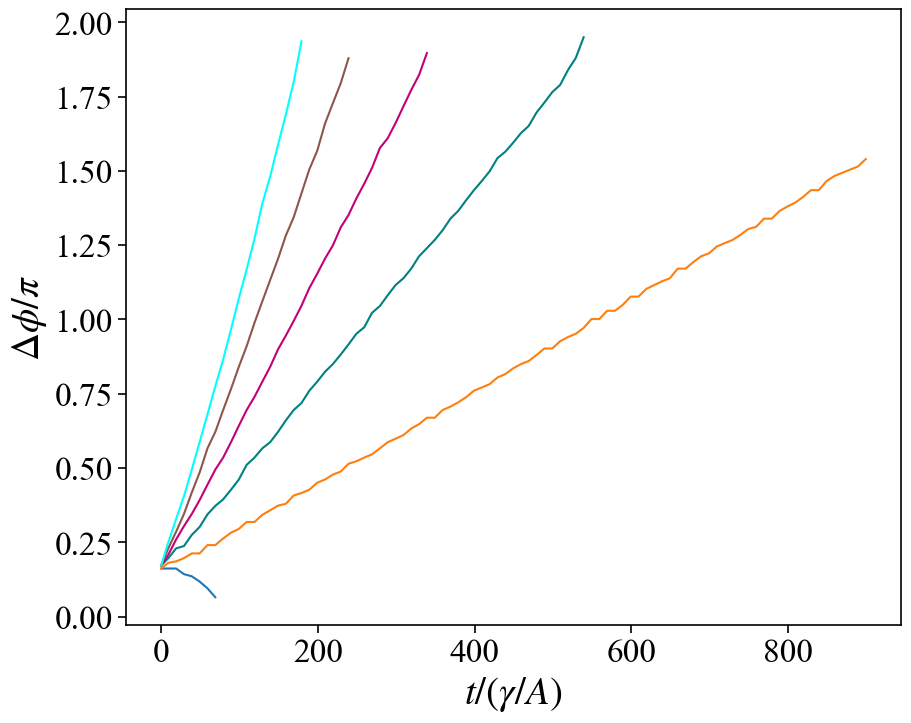

In [14]:
color_array= ['tab:blue', 'tab:orange', 'teal', 'xkcd:magenta', 'tab:brown', 'cyan']

for phi in phi_set[1:2]:
    for rho in rho_set[1:2]:
        r=np.sqrt(rho)
        fig, axs = plt.subplots(1, 1, figsize=(10, 8), sharex=False)
        for i,alpha0 in np.ndenumerate(alpha0_set):
            
            data = all_data[np.isclose(all_data['alpha0'], alpha0) &  np.isclose(all_data['rho'], rho) & (all_data['phi_param'] == phi)&  np.isclose(all_data['r_param'], r)]
            data=data.sort_values(by='t')
            # axs[0].scatter( data['phi_max'], data['total_free_energy'],s=1, label = "$\\alpha_0$ = {0:.2f}".format(alpha0))
            axs.plot(data['t'], (data['phi_max']-data['phi_min'])/pi, label = "$\\alpha_0$ = {0:.2f}$\\pi$".format(alpha0/pi), color = color_array[i[0]])
        # axs.set_title("$\\rho$=1/e^({0:.2f}), $\\Delta\\phi_0$={1:.2f}$\\pi$".format(np.log(1/rho), 2*phi/pi))
        # axs[0].set_xlabel("$\\phi (\\delta_{max})$")
        axs.set_ylabel("$\\Delta\\phi/\\pi$")
        # axs[1].set_ylabel("$F$")
        axs.set_xlabel("$t/(\\gamma/A)$")
        # axs.legend()
        plt.savefig('Figures/dphi_time.pdf', dpi =300)